# Lab 3 — Supervised Learning: Regression Algorithms
**Student:** Zeynep Ozdemir
**Student ID:** 9045142 
**Section:** Section 1

**Objective:** (A) Identify fraudulent credit-card transactions with
logistic regression; (B) predict insurance charges using linear regression.
For both models, use a 70/30 train/test split and evaluate performance.



In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import (accuracy_score, confusion_matrix,
    classification_report, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score,
    mean_absolute_error, mean_squared_error, r2_score)

sns.set_theme(style='whitegrid')
RANDOM_STATE = 42


# PART A — CREDIT CARD FRAUD DETECTION

## Exploratory Data Analysis (EDA) and Data Preprocessing Checks
In this section, I am loading the dataset and performing Exploratory Data Analysis (EDA) by inspecting the DataFrame, checking null values and duplicated rows. I also check the data before preprocessing, identify the classification labels, and calculate the percentages of fraudulent and legitimate transactions. The results show that the dataset is highly imbalanced, with 99.827% legitimate transactions and only 0.173% fraudulent transactions.

In [6]:
fraud_df = pd.read_csv('data/creditcard.csv')
print('Shape:', fraud_df.shape)
display(fraud_df.head())
fraud_df.info()
print('Missing values:', fraud_df.isnull().sum().sum())
print('Duplicate rows:', fraud_df.duplicated().sum())
print('Class counts:')
print(fraud_df['Class'].value_counts())
print('Class percentages:')
print((fraud_df['Class'].value_counts(normalize=True)*100).round(3))


Shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

Based on the Kaggle dataset information, Class 0 represents legitimate transactions, while Class 1 represents fraudulent transactions.

# Class Distribution Visualization

In this section, I am visualizing and comparing legitimate and fraudulent transactions using a count plot. The graph shows that legitimate transactions (Class 0) are much higher than fraudulent transactions (Class 1), which makes the fraud bar almost invisible. This indicates that the dataset is highly imbalanced, and accuracy alone may not be enough to evaluate the fraud detection model.

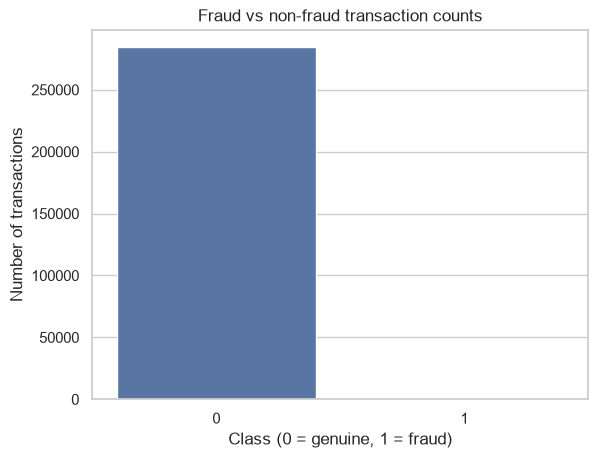

In [7]:
sns.countplot(data=fraud_df, x='Class')
plt.title('Fraud vs non-fraud transaction counts')
plt.xlabel('Class (0 = genuine, 1 = fraud)')
plt.ylabel('Number of transactions')
plt.show()

# Feature Selection and Train/Test Split

In this section, first we extract the independent variables (features) by removing the column assigned as the dependent variable (target) that we want to predict. Then, we split the dataset into 70% training and 30% testing data. We also use stratify=y_fraud because legitimate transactions are much more common than fraudulent transactions, so we maintain similar proportions of both classes in the training and testing datasets for more reliable model evaluation.

In [9]:
X_fraud = fraud_df.drop(columns='Class')
y_fraud = fraud_df['Class']

Xf_train, Xf_test, yf_train, yf_test = train_test_split(
    X_fraud, y_fraud, test_size=0.30,
    random_state=RANDOM_STATE, stratify=y_fraud)

print('Training rows:', len(Xf_train))
print('Testing rows:', len(Xf_test))
print('Train fraud labels:', yf_train.value_counts().to_dict())
print('Test fraud labels:', yf_test.value_counts().to_dict())


Training rows: 199364
Testing rows: 85443
Train fraud labels: {0: 199020, 1: 344}
Test fraud labels: {0: 85295, 1: 148}


In [10]:
fraud_model = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(max_iter=1000,
                                 class_weight='balanced',
                                 random_state=RANDOM_STATE))
])
fraud_model.fit(Xf_train, yf_train)
yf_pred = fraud_model.predict(Xf_test)
yf_scores = fraud_model.predict_proba(Xf_test)[:, 1]
print('Logistic regression model trained.')


Logistic regression model trained.
